In [2]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

STAGES = ["Wake", "N1", "N2", "N3", "REM"]  # AASM 5-class order
EPOCH_MIN = 0.5                             # 1 epoch = 30 s = 0.5 min

# One fixed hue per stage; accent/muted pair for emphasis charts
STAGE_COLORS = dict(zip(STAGES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
ACCENT, ACCENT_TINT, MUTED = "#2a78d6", "#b7d3f6", "#898781"
INK, INK_2, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e1e0d9"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": ["Segoe UI", "DejaVu Sans"], "text.color": INK,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlelocation": "left", "axes.titleweight": "bold",
    "axes.titlesize": 12, "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})

In [3]:
# Locate the repo root regardless of the notebook's working directory
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "results" / "eda").is_dir())
FIG_DIR, TAB_DIR = ROOT / "results" / "figures", ROOT / "results" / "tables"
FIG_DIR.mkdir(exist_ok=True)
TAB_DIR.mkdir(exist_ok=True)

with open(ROOT / "results" / "eda" / "eda_records.json", encoding="utf-8") as f:
    df = pd.DataFrame(json.load(f))

# Expand epoch counts: 5 AASM classes + Movement time + Unscored
LABELS = STAGES + ["MT", "Unscored"]
for tag in ("full", "trim"):
    counts = pd.DataFrame(df.pop(tag).tolist(), columns=LABELS).add_prefix(f"{tag}_")
    df = pd.concat([df, counts], axis=1)
FULL_COLS = [f"full_{s}" for s in STAGES]
TRIM_COLS = [f"trim_{s}" for s in STAGES]

df["group"] = np.where(df["set"] == "cassette", "SC", "ST")
df["subject_no"] = df["subject"].str[2:].astype(int)

sc = df[df["group"] == "SC"]       # SC-78: all Sleep-Cassette recordings
sc20 = sc[sc["subject_no"] < 20]   # SC-20: subjects 00-19
st = df[df["group"] == "ST"]       # ST: Sleep-Telemetry (not used for training)
print(df.shape)

(197, 29)


In [4]:
# Sanity checks against independently verified numbers
assert len(df) == 197 and len(sc) == 153 and len(st) == 44 and len(sc20) == 39
expected = {"Wake": 65941, "N1": 21522, "N2": 69132, "N3": 13039, "REM": 25835}
assert {s: int(sc[f"trim_{s}"].sum()) for s in STAGES} == expected
print("All checks passed")

All checks passed


In [5]:
def overview(d):
    return pd.Series({
        "Recordings": len(d),
        "Subjects": d["subject"].nunique(),
        "Age range (yr)": f"{d['age'].min()}-{d['age'].max()}",
        "Mean duration (h)": round(d["hours"].mean(), 1),
        "Total duration (h)": round(d["hours"].sum(), 1),
        "Labelled epochs, trimmed": int(d[TRIM_COLS].sum().sum()),
    })

summary = pd.DataFrame({"SC-78": overview(sc), "SC-20": overview(sc20),
                        "ST": overview(st), "All": overview(df)})
summary.to_csv(TAB_DIR / "01_dataset_overview.csv")
summary

,SC-78,SC-20,ST,All
Recordings,153,39,44,197
Subjects,78,20,22,100
Age range (yr),25-101,25-34,18-78,18-101
Mean duration (h),22.7,22.9,8.6,19.5
Total duration (h),3470.2,894.8,378.8,3849.0
"Labelled epochs, trimmed",195469,42307,42467,237936


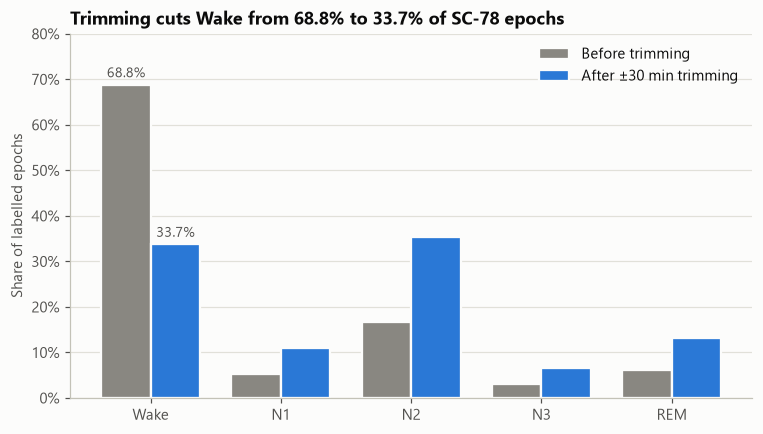

,Before (%),After (%)
Wake,68.8,33.7
N1,5.2,11.0
N2,16.7,35.4
N3,3.1,6.7
REM,6.2,13.2


In [6]:
def class_share(d, cols):
    c = d[cols].sum()
    return (c / c.sum() * 100).set_axis(STAGES)

before, after = class_share(sc, FULL_COLS), class_share(sc, TRIM_COLS)

x, w = np.arange(len(STAGES)), 0.38
fig, ax = plt.subplots(figsize=(8, 4.3))
b1 = ax.bar(x - w / 2, before, w, color=MUTED, edgecolor=SURFACE, linewidth=1.5, label="Before trimming")
b2 = ax.bar(x + w / 2, after, w, color=ACCENT, edgecolor=SURFACE, linewidth=1.5, label="After ±30 min trimming")
# Label only the Wake pair, which carries the message
for bars in (b1, b2):
    ax.bar_label(bars, labels=[f"{v.get_height():.1f}%" if i == 0 else "" for i, v in enumerate(bars)],
                 padding=3, fontsize=9, color=INK_2)
ax.set_xticks(x, STAGES)
ax.set_ylim(0, 80)
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set_ylabel("Share of labelled epochs")
ax.set_title(f"Trimming cuts Wake from {before['Wake']:.1f}% to {after['Wake']:.1f}% of SC-78 epochs")
ax.legend(frameon=False)
fig.savefig(FIG_DIR / "01_class_share_before_after.png")
plt.show()

pd.DataFrame({"Before (%)": before, "After (%)": after}).round(1)

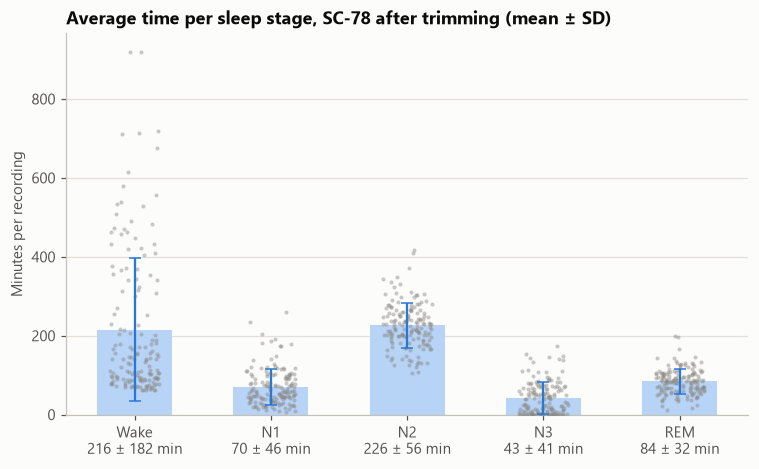

,mean,std,median
Wake,215.5,182.1,140.5
N1,70.3,45.9,59.0
N2,225.9,56.5,224.0
N3,42.6,40.6,39.0
REM,84.4,31.5,84.5


In [7]:
minutes = sc[TRIM_COLS].mul(EPOCH_MIN).set_axis(STAGES, axis=1)
stats = minutes.agg(["mean", "std", "median"]).T.round(1)

rng = np.random.default_rng(0)  # fixed seed -> reproducible jitter
x = np.arange(len(STAGES))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x, stats["mean"], width=0.55, color=ACCENT_TINT, zorder=2)
ax.errorbar(x, stats["mean"], yerr=stats["std"], fmt="none", ecolor=ACCENT, capsize=4, lw=1.5, zorder=4)
for i, s in enumerate(STAGES):  # one dot per recording
    ax.scatter(x[i] + rng.uniform(-0.18, 0.18, len(minutes)), minutes[s],
               s=7, color=MUTED, alpha=0.45, linewidths=0, zorder=3)
ax.set_xticks(x, [f"{s}\n{stats.loc[s, 'mean']:.0f} ± {stats.loc[s, 'std']:.0f} min" for s in STAGES])
ax.set_ylim(bottom=0)
ax.set_ylabel("Minutes per recording")
ax.set_title("Average time per sleep stage, SC-78 after trimming (mean ± SD)")
fig.savefig(FIG_DIR / "01_minutes_per_stage.png")
plt.show()

stats

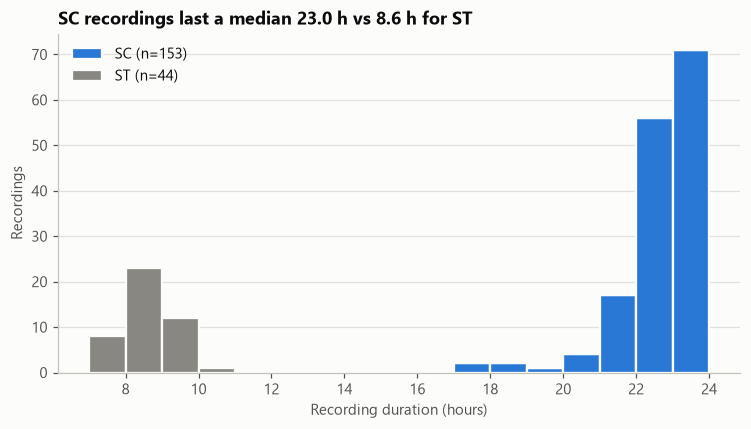

In [8]:
bins = np.arange(7, 25, 1)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist([sc["hours"], st["hours"]], bins=bins, stacked=True, color=[ACCENT, MUTED],
        edgecolor=SURFACE, linewidth=1.5, label=[f"SC (n={len(sc)})", f"ST (n={len(st)})"])
ax.set_xticks(range(8, 25, 2))
ax.set_xlabel("Recording duration (hours)")
ax.set_ylabel("Recordings")
ax.set_title(f"SC recordings last a median {sc['hours'].median():.1f} h vs {st['hours'].median():.1f} h for ST")
ax.legend(frameon=False)
fig.savefig(FIG_DIR / "01_recording_duration.png")
plt.show()

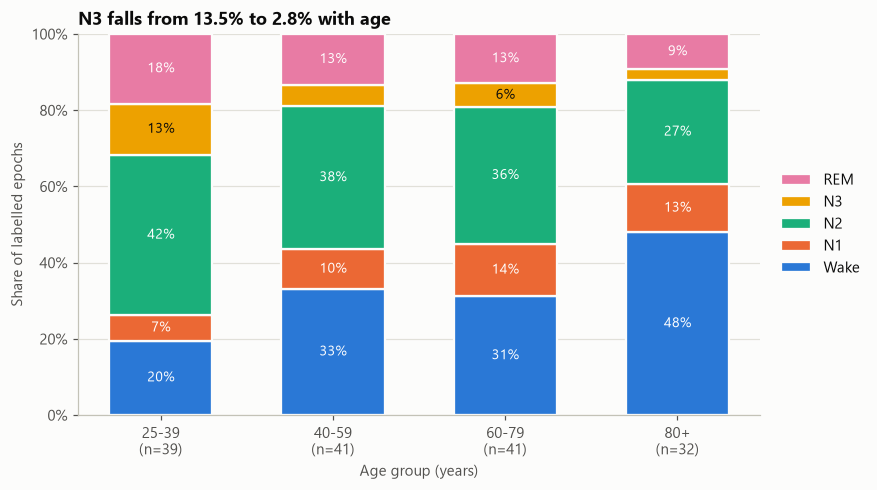

,Wake,N1,N2,N3,REM
age_group,,,,,
25-39,19.6,6.6,42.1,13.5,18.2
40-59,33.2,10.3,37.7,5.5,13.4
60-79,31.2,13.7,35.9,6.2,13.0
80+,48.0,12.6,27.3,2.8,9.3


In [9]:
age_bins, age_labels = [24, 39, 59, 79, 120], ["25-39", "40-59", "60-79", "80+"]
grp = sc.assign(age_group=pd.cut(sc["age"], bins=age_bins, labels=age_labels))
by_age = grp.groupby("age_group", observed=True)
share = by_age[TRIM_COLS].sum().set_axis(STAGES, axis=1)
share = share.div(share.sum(axis=1), axis=0) * 100
n_rec = by_age.size()

xpos, bottoms = np.arange(len(share)), np.zeros(len(share))
fig, ax = plt.subplots(figsize=(8, 4.5))
for s in STAGES:
    ax.bar(xpos, share[s], bottom=bottoms, width=0.6, color=STAGE_COLORS[s],
           edgecolor=SURFACE, linewidth=1.5, label=s)
    for i, v in enumerate(share[s]):
        if v >= 6:  # label only segments large enough to hold text
            ax.text(xpos[i], bottoms[i] + v / 2, f"{v:.0f}%", ha="center", va="center",
                    fontsize=9, color=INK if s == "N3" else "white")
    bottoms += share[s].to_numpy()
ax.set_xticks(xpos, [f"{g}\n(n={n_rec[g]})" for g in share.index])
ax.set_xlabel("Age group (years)")
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set_ylabel("Share of labelled epochs")
ax.set_title(f"N3 falls from {share['N3'].iloc[0]:.1f}% to {share['N3'].iloc[-1]:.1f}% with age")
h, l = ax.get_legend_handles_labels()
ax.legend(h[::-1], l[::-1], frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.savefig(FIG_DIR / "01_stage_by_age.png")
plt.show()

share.round(1)